In [ ]:
import numpy as np
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.2195 - val_loss: 0.1394
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1246 - val_loss: 0.1126
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1079 - val_loss: 0.1011
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0995 - val_loss: 0.0955
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0949 - val_loss: 0.0918
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0921 - val_loss: 0.0894
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0897 - val_loss: 0.0877
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0879 - val_loss: 0.0860
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0865 - val_loss: 0.0846
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0851 - val_loss: 0.0839
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0841 - val_loss: 0.0826


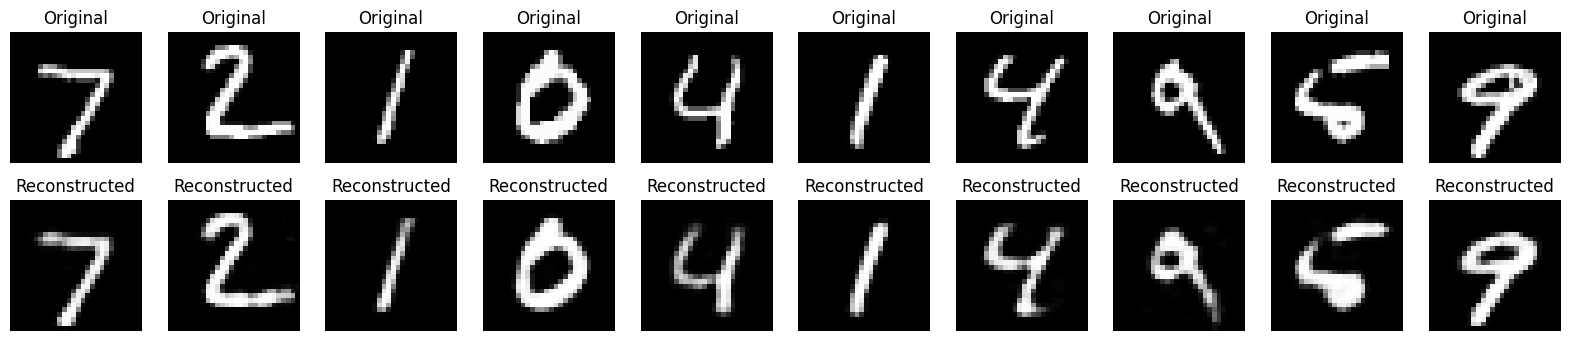

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Shape of encoded data: (10000, 64)


In [ ]:
# Load dataset (you can replace MNIST with your own dataset)
(x_train, _), (x_test, _) = mnist.load_data()

# Normalize data
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images
x_train = x_train.reshape((x_train.shape[0], -1))  # 28x28 -> 784
x_test = x_test.reshape((x_test.shape[0], -1))

input_dim = x_train.shape[1]  # 784

# Define the autoencoder
encoding_dim = 64  # Number of neurons in the bottleneck layer

# Encoder
input_layer = Input(shape=(input_dim,))
encoded = Dense(128, activation="relu")(input_layer)
encoded = Dense(encoding_dim, activation="relu")(encoded)

# Decoder
decoded = Dense(128, activation="relu")(encoded)
decoded = Dense(input_dim, activation="sigmoid")(decoded)

# Autoencoder model
autoencoder = Model(input_layer, decoded)

# Encoder model for encoding data
encoder = Model(input_layer, encoded)

# Compile the autoencoder
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

# Train the autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
)

# Visualize reconstruction performance
def visualize_reconstruction(autoencoder, x_test, n=10):
    decoded_imgs = autoencoder.predict(x_test[:n])
    plt.figure(figsize=(20, 4))

    for i in range(n):
        # Original images
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
        plt.title("Original")
        plt.axis("off")

        # Reconstructed images
        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
        plt.title("Reconstructed")
        plt.axis("off")

    plt.show()

visualize_reconstruction(autoencoder, x_test)

# Encode real-world data
encoded_data = encoder.predict(x_test)

print(f"Shape of encoded data: {encoded_data.shape}")